# River flow: checking the range, not only the forecast

**Our first 90% range for a river's flow held 94% of the time. It was as wide in August as in the April snowmelt, and its low end was below zero in seven forecasts out of ten.**

Whoever operates a weir or issues a flood warning cannot use a single number. They need a range: how high could the river be three days from now? We forecast the daily flow of the Saugeen River in Ontario three days ahead with a simple model that gives a 90% range, and we check the range as carefully as the forecast. One argument repairs it for ordinary days. Nothing in this notebook repairs it for the days the river rises fast, and the run shows how badly it fails there.

*Data: daily mean flow of the Saugeen River at Walkerton, Ontario, 1950 to 1979, from the Monash Time Series Forecasting Archive, CC BY 4.0 ([source and license](data/README.md#river-flow)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import GaussianAR1Forecaster, LastValueForecaster, Pipeline, Scenario, cases_from_series
from timegym.target import LogTransform

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## The river

The flow is in cubic meters per second, one value per day. Most of the year the river is low and quiet. In March and April the snow melts: a typical April day carries seven times the flow of a typical August day, and the peaks go far higher.

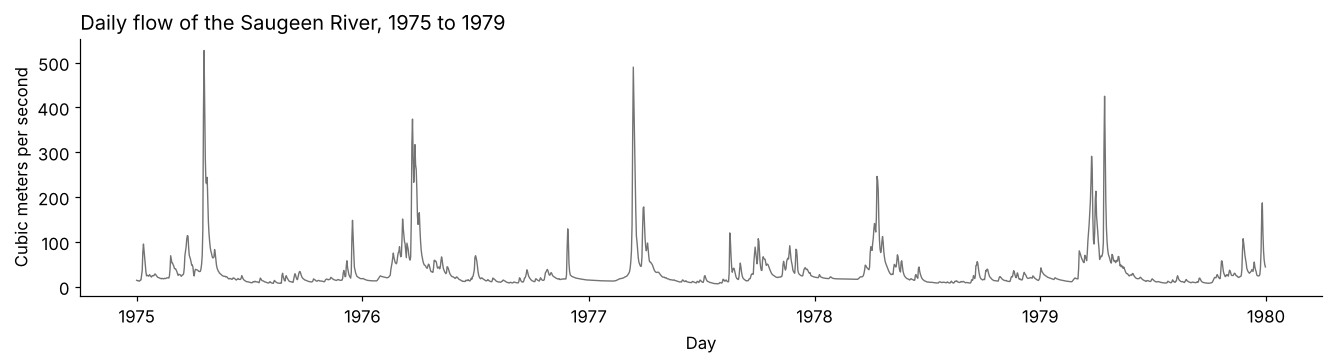

10,957 days. Half of all days are below 18 cubic meters per second; the highest day reached 578.
A typical August day: 9. A typical April day: 67.


In [2]:
river = load("river-flow")
flow = river["flow"]

fig, ax = plt.subplots(figsize=(12, 3.2), layout="constrained")
recent = flow.loc["1975":]
ax.plot(recent.index, recent, color="0.45", linewidth=0.9)
ax.set(title="Daily flow of the Saugeen River, 1975 to 1979", xlabel="Day", ylabel="Cubic meters per second")
plt.show()

by_month = flow.groupby(flow.index.month).median()
print(f"{len(flow):,} days. Half of all days are below {flow.median():.0f} cubic meters per second; the highest day reached {flow.max():.0f}.")
print(f"A typical August day: {by_month[8]:.0f}. A typical April day: {by_month[4]:.0f}.")

## A forecast with a range

`GaussianAR1Forecaster` is one of the simplest models that gives a range. It assumes that the flow drifts back toward its usual level a little each day, and that what it cannot predict is bell-shaped noise of a fixed size. For each day ahead it returns three numbers: the flow it expects to be exceeded 95% of the time, half of the time and 5% of the time. The first and last are the ends of a 90% range.

We forecast three days ahead from every fifth day of 1960 to 1979, each time from the history before that day. `LastValueForecaster`, which repeats the last flow it saw, runs on the same cases as the reference for the middle forecast.

TimeGym checks every range before it scores it (the three numbers must be in order, for every day asked for) and records two things per case without being asked: `interval_coverage`, the share of the three days on which the flow landed inside the range, and `interval_width`.

In [3]:
horizon = 3
first = int((river.index < "1960-01-01").sum())
cases = cases_from_series(river, origins=range(first, len(river) - horizon + 1, 5), horizon=horizon, name="river")

levels = (0.05, 0.5, 0.95)
plain = Pipeline(GaussianAR1Forecaster(levels=levels))
runs = {"Last value": Pipeline(LastValueForecaster()).run(cases=cases),
        "Range, on the flow itself": plain.run(cases=cases, keep_data=True)}


def per_case(run, score):
    return run.metrics[score].to_numpy()


def summary(run):
    row = {"Average error of the middle forecast": per_case(run, "mae").mean()}
    if "interval_coverage" in run.metrics:
        row["Days inside the 90% range (%)"] = 100 * per_case(run, "interval_coverage").mean()
        row["Typical width of the range"] = np.median(per_case(run, "interval_width"))
    return row


results = pd.DataFrame({name: summary(run) for name, run in runs.items()}).T
display(results.round(1))

checks = runs["Range, on the flow itself"].report.summary["status_counts"]
print(f"{len(cases):,} forecasts of {horizon} days each. Output checks passed: {checks['PASS']}, failed: {checks['FAIL']}.")
first_look = results.loc["Range, on the flow itself"]
assert 93 < first_look["Days inside the 90% range (%)"] < 96 and checks["FAIL"] == 0

,Average error of the middle forecast,Days inside the 90% range (%),Typical width of the range
Last value,8.3,NaN,NaN
"Range, on the flow itself",8.4,94.3,58.3


1,461 forecasts of 3 days each. Output checks passed: 1461, failed: 0.


The flow landed inside the 90% range on 94% of days. A range that promises 90% and delivers 94% looks safe, even a little generous. The middle forecast is no better than repeating the last value, but we came for the range, and one number says it is fine.

## Look inside the average

That 94% is an average over twenty years of days. The run kept every case, so we can ask the same question month by month, and look at the ranges themselves.

In [4]:
start_month = np.array([case.observed.index[0].month for case in cases])
actual = np.array([case.observed["flow"].to_numpy() for case in cases])


def ranges(run):
    "Low end, middle and high end of the range for every case and day ahead."
    quantiles = np.array([entry.forecast.quantiles[:, 0, :] for entry in run.cases])
    return quantiles[..., 0], quantiles[..., 1], quantiles[..., 2]


def by_month(run):
    table = pd.DataFrame({"month": start_month,
                          "Days inside the 90% range (%)": 100 * per_case(run, "interval_coverage"),
                          "Width of the range": per_case(run, "interval_width")})
    grouped = table.groupby("month")
    return pd.DataFrame({"Days inside the 90% range (%)": grouped["Days inside the 90% range (%)"].mean(),
                         "Typical width of the range": grouped["Width of the range"].median(),
                         "Typical flow": pd.Series(actual.mean(axis=1)).groupby(start_month).median()})


plain_months = by_month(runs["Range, on the flow itself"])
display(plain_months.set_axis(MONTHS).round(0).astype(int).T)

low, _, _ = ranges(runs["Range, on the flow itself"])
below_zero = 100 * (low < 0).mean()
print(f"The low end of the range is below zero in {below_zero:.0f}% of the forecasts.")
assert below_zero > 60
assert plain_months["Days inside the 90% range (%)"].loc[[7, 8, 9]].min() > 98
assert plain_months["Days inside the 90% range (%)"].loc[[3, 4]].max() < 85
assert plain_months["Typical width of the range"].max() - plain_months["Typical width of the range"].min() < 3

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Days inside the 90% range (%),97,98,82,76,95,98,100,99,100,99,95,93
Typical width of the range,58,58,58,59,59,59,58,58,58,58,58,58
Typical flow,18,19,37,58,29,16,11,10,9,12,19,21


The low end of the range is below zero in 71% of the forecasts.


The range is about 58 cubic meters per second wide in every month. In August the river carries about 10, so a range 58 wide runs from well below zero to several times the flow, and it is right almost every day because it could hardly be wrong. In March and April, when it matters, it holds on about four days in five. Too wide all summer and too narrow in spring averages out to 94%.

The cause is the model's assumption that its errors have a fixed size. A river's do not: its swings grow with its flow.

## One argument

A standard repair is to forecast the logarithm of the flow. On that scale a swing from 10 to 20 is the same size as one from 100 to 200, which suits a river much better. In TimeGym this is an argument of the pipeline, `target_transform=LogTransform()`. The model works on the transformed flow, and the pipeline converts the forecast and its range back, so everything we score is still in cubic meters per second.

,Average error of the middle forecast,Days inside the 90% range (%),Typical width of the range
Last value,8.3,NaN,NaN
"Range, on the flow itself",8.4,94.3,58.3
"Range, on the log of the flow",8.0,89.5,14.5


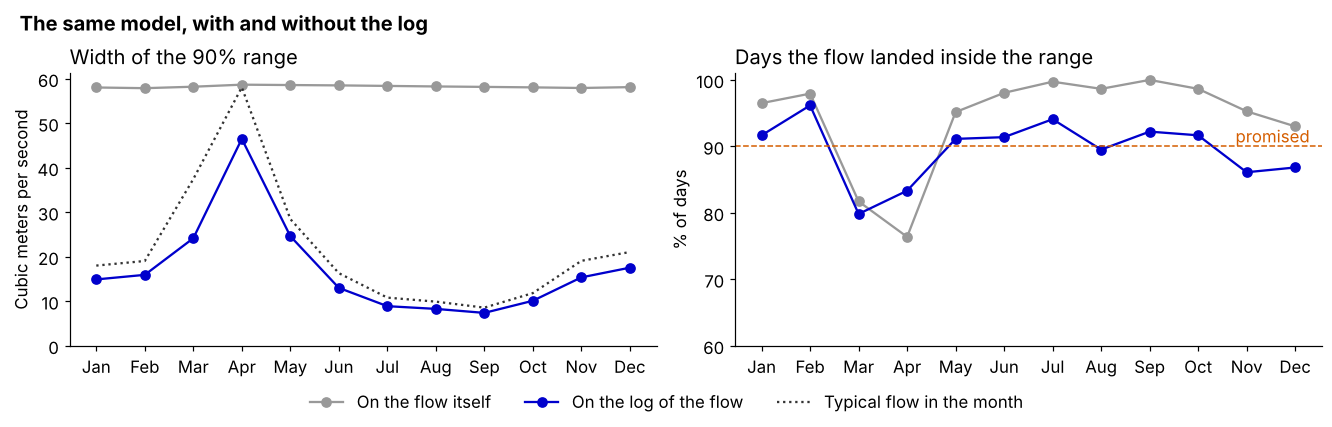

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Days inside the 90% range (%),92,96,80,83,91,91,94,90,92,92,86,87
Typical width of the range,15,16,24,47,25,13,9,8,7,10,15,18
Typical flow,18,19,37,58,29,16,11,10,9,12,19,21


In [5]:
logged = Pipeline(GaussianAR1Forecaster(levels=levels), target_transform=LogTransform())
runs["Range, on the log of the flow"] = logged.run(cases=cases, keep_data=True)
results = pd.DataFrame({name: summary(run) for name, run in runs.items()}).T
display(results.round(1))

log_months = by_month(runs["Range, on the log of the flow"])
log_low, _, _ = ranges(runs["Range, on the log of the flow"])

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
x = np.arange(12)
for months, color, label in ((plain_months, "0.6", "On the flow itself"), (log_months, "#0000CC", "On the log of the flow")):
    left.plot(x, months["Typical width of the range"], color=color, marker="o", label=label)
    right.plot(x, months["Days inside the 90% range (%)"], color=color, marker="o", label=label)
left.plot(x, plain_months["Typical flow"], color="0.2", linestyle=":", label="Typical flow in the month")
left.set(title="Width of the 90% range", ylabel="Cubic meters per second", xticks=x, xticklabels=MONTHS, ylim=(0, None))
right.axhline(90, color="#D55E00", linestyle="--", linewidth=1)
right.text(11.3, 90, "promised", color="#D55E00", va="bottom", ha="right")
right.set(title="Days the flow landed inside the range", ylabel="% of days", xticks=x, xticklabels=MONTHS, ylim=(60, 101))
fig.legend(*left.get_legend_handles_labels(), loc="outside lower center", ncols=3)
fig.suptitle("The same model, with and without the log", x=0.01, ha="left", fontweight="bold")
plt.show()
display(log_months.set_axis(MONTHS).round(0).astype(int).T)

after = results.loc["Range, on the log of the flow"]
assert runs["Range, on the log of the flow"].report.summary["status_counts"]["FAIL"] == 0   # every range in order
assert 88 < after["Days inside the 90% range (%)"] < 92 and (log_low > 0).all()
assert after["Typical width of the range"] < first_look["Typical width of the range"] / 3
assert log_months["Typical width of the range"].loc[4] > 4 * log_months["Typical width of the range"].loc[9]
assert log_months["Days inside the 90% range (%)"].between(78, 97).all()

With the log, the flow lands inside the range on 89.5% of days, almost exactly the 90% it promises. The typical range is four times narrower, 14 against 58, and it is never below zero. It also moves with the river: about 7 wide in September and 47 in April. The middle forecast improved a little as well.

The coverage by month is not perfect, between 80% and 96%, but no month is far from honest any more. This is the range to hand over for ordinary days.

## Is the range code itself right?

Before trusting any of these percentages there is something to rule out. If the model computed its ranges wrongly, every coverage number above would be wrong too, and the river could not tell us. Generated data can. We give the same forecaster 300 series of exactly the kind it assumes, flow that drifts back to a level with bell-shaped noise, where a correct 90% range must hold 90% of the time.

In [6]:
assumed = Scenario("ar1", history_length=400, horizon=horizon, parameters={"phi": 0.9, "sigma": 1.0})
generated = plain.run(scenarios=[assumed], instances=300)
generated_coverage = 100 * per_case(generated, "interval_coverage").mean()
print(f"On {len(generated.cases)} generated series that match the model's assumptions, "
      f"the 90% range holds on {generated_coverage:.1f}% of days.")
assert 87 < generated_coverage < 93

On 300 generated series that match the model's assumptions, the 90% range holds on 90.6% of days.


91% where 90% is the right answer. The range code does what it says when the model's assumptions are true, so the misses on the river come from the river not behaving as the model assumes. That is a statement about the data we can now make with a clear conscience.

## The days that matter

A flow forecast earns its keep on the days the river rises. We mark every case in which the flow at least doubles within the three days being forecast, and score those cases apart from the rest.

In [7]:
last_seen = np.array([case.task.history["flow"].iloc[-1] for case in cases])
rising = actual.max(axis=1) >= 2 * last_seen

rows = {}
for name, run in runs.items():
    error = per_case(run, "mae")
    row = {("Average error", "calm"): error[~rising].mean(), ("Average error", "rising"): error[rising].mean()}
    if "interval_coverage" in run.metrics:
        coverage = 100 * per_case(run, "interval_coverage")
        row[("Days inside the 90% range (%)", "calm")] = coverage[~rising].mean()
        row[("Days inside the 90% range (%)", "rising")] = coverage[rising].mean()
    rows[name] = row
split = pd.DataFrame(rows).T
display(split.round(1))
print(f"{rising.sum()} of the {len(cases):,} cases are rising cases, {100 * rising.mean():.0f}% of them.")

error = split["Average error"]
assert error["rising"].max() - error["rising"].min() < 1.5 and error["rising"].min() > 5 * error["calm"].max()
inside = split["Days inside the 90% range (%)"]
assert inside.loc["Range, on the log of the flow", "rising"] < 35
assert inside.loc["Range, on the log of the flow", "calm"] > 90

Average error         \
                                       calm rising   
Last value                              6.4   36.3   
Range, on the flow itself               6.6   36.1   
Range, on the log of the flow           6.1   36.3   

                              Days inside the 90% range (%)         
                                                       calm rising  
Last value                                              NaN    NaN  
Range, on the flow itself                              96.3   62.6  
Range, on the log of the flow                          93.7   25.2

90 of the 1,461 cases are rising cases, 6% of them.


On the 90 rising cases every forecaster misses by about 36 cubic meters per second, more than five times its error on calm days, and the three are within a point of each other. The model with the log, the model without it and "repeat the last value" know equally little about a rise before it starts.

The ranges fail there too, and the better range fails worse. With the log, the flow lands inside the range on a quarter of rising days. The narrow range that is honest on calm days is exactly what a rising river leaves behind. The wide range without the log catches more of them only because it is wide all year.

No setting of this model will fix that. A rise comes from rain or a thaw, and neither is in the history of the flow. What the run gives us is a precise description of the product: a range that can be trusted on ordinary days, and that should not be used as a flood warning.

## What TimeGym added

- Ranges as a checked and scored output. Every forecast's range passed the output checks, and coverage and width were recorded per case with no extra code.
- A transform as one argument of the pipeline, with forecasts and ranges returned in the river's own units, so the two versions could be compared on the same footing.
- A run on generated series where the model's assumptions are true, which separated "the range code is wrong" from "the river does not behave as assumed".
- Every case kept, so one average could be split by month and by rising days. Both splits changed the conclusion.

## Change one thing

- Ask for a narrower range with `levels=(0.25, 0.5, 0.75)` and check whether it holds half of the time.
- Forecast a week ahead with `horizon=7`. The range should widen with each day ahead; does its coverage hold?
- Swap `LogTransform()` for `BoxCoxTransform()` from `timegym.target`, which chooses its own curve.
- Change the definition of a rising case from doubling to a 50% rise and see how the split moves.
- `load("river-flow", full=True)` goes back to 1915.

**What this doesn't show.** The data has no rainfall, snow depth or upstream gauge, which is what a real flood forecast runs on. The flow is a daily mean, not the peak level at a bridge. "Rising" is our own definition, and 90 cases is a small group, so its percentages are rough. The ranges are for each day separately: they say nothing about the chance that all three days stay inside.

**Related:** [Univariate uncertainty](../tutorials/08_univariate_uncertainty.ipynb) explains ranges and how they are scored, [Target transforms](../tutorials/04_target_transforms.ipynb) covers `LogTransform` and its relatives, and the reference lists the [uncertainty scores](../docs/api/diagnostics.md#uncertainty-scores). More examples are on the [examples page](../docs/examples.md).